# EXPERIMENT NO. 11B Analyzing Sales Performance by Region in a Retail Company

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("customer_shopping_data.csv")

df.head()

,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,5/8/2022,Kanyon
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,12/12/2021,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,9/11/2021,Metrocity
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,16/05/2021,Metropol AVM
4,I337046,C189076,Female,53,Books,4,60.60,Cash,24/10/2021,Kanyon


In [2]:
df["sales_amount"] = df["quantity"] * df["price"]

In [3]:
# Total sales by shopping mall
mall_sales = df.groupby("shopping_mall")["sales_amount"].sum()
mall_sales

shopping_mall
Cevahir AVM          12645138.20
Emaar Square Mall    12406100.29
Forum Istanbul       12303921.24
Istinye Park         24618827.68
Kanyon               50554231.10
Mall of Istanbul     50872481.68
Metrocity            37302787.33
Metropol AVM         25379913.19
Viaport Outlet       12521339.72
Zorlu Center         12901053.82
Name: sales_amount, dtype: float64

In [4]:
# Total sales by shopping mall
mall_sales = df.groupby("shopping_mall")["sales_amount"].sum()
mall_sales

shopping_mall
Cevahir AVM          12645138.20
Emaar Square Mall    12406100.29
Forum Istanbul       12303921.24
Istinye Park         24618827.68
Kanyon               50554231.10
Mall of Istanbul     50872481.68
Metrocity            37302787.33
Metropol AVM         25379913.19
Viaport Outlet       12521339.72
Zorlu Center         12901053.82
Name: sales_amount, dtype: float64

In [5]:
# Total sales by category
category_sales = df.groupby("category")["sales_amount"].sum()
category_sales

category
Books              8.345529e+05
Clothing           1.139968e+08
Cosmetics          6.792863e+06
Food & Beverage    8.495351e+05
Shoes              6.655345e+07
Souvenir           6.358247e+05
Technology         5.786235e+07
Toys               3.980426e+06
Name: sales_amount, dtype: float64

In [6]:
# Top-performing malls
mall_sales.sort_values(ascending=False)

shopping_mall
Mall of Istanbul     50872481.68
Kanyon               50554231.10
Metrocity            37302787.33
Metropol AVM         25379913.19
Istinye Park         24618827.68
Zorlu Center         12901053.82
Cevahir AVM          12645138.20
Viaport Outlet       12521339.72
Emaar Square Mall    12406100.29
Forum Istanbul       12303921.24
Name: sales_amount, dtype: float64

In [7]:
# Sales by mall and category
mall_category_sales = df.groupby(
    ["shopping_mall", "category"]
)["sales_amount"].sum()

mall_category_sales

shopping_mall  category       
Cevahir AVM    Books                44541.00
               Clothing           5706321.28
               Cosmetics           321214.00
               Food & Beverage      44010.45
               Shoes              3243918.85
                                     ...    
Zorlu Center   Food & Beverage      41955.06
               Shoes              3535601.47
               Souvenir             28996.56
               Technology         2987250.00
               Toys                197550.08
Name: sales_amount, Length: 80, dtype: float64

In [8]:
# Pivot table
pivot = df.pivot_table(
    index="shopping_mall",
    columns="category",
    values="sales_amount",
    aggfunc="sum"
)

pivot

category,Books,Clothing,Cosmetics,Food & Beverage,Shoes,Souvenir,Technology,Toys
shopping_mall,,,,,,,,
Cevahir AVM,44541.00,5706321.28,321214.00,44010.45,3243918.85,29723.82,3051300.0,204108.80
Emaar Square Mall,41995.80,5590490.40,338941.76,40610.95,3089675.16,30943.74,3094350.0,179092.48
Forum Istanbul,42056.40,5792444.24,353172.76,39162.24,3327942.65,32879.19,2516850.0,199413.76
Istinye Park,76083.30,11253900.24,655357.88,85918.44,6641481.22,68925.48,5436900.0,400261.12
Kanyon,163029.15,22609527.60,1369550.78,166497.05,13383190.83,127399.53,11944800.0,790236.16
Mall of Istanbul,172240.35,22947417.68,1367517.78,171177.90,13467814.80,127540.29,11828250.0,790522.88
Metrocity,125911.65,17226692.56,991860.04,129902.74,9519296.37,94227.09,8608950.0,605946.88
Metropol AVM,83718.90,11568084.00,680770.38,88638.04,7149825.21,67869.78,5327700.0,413306.88
Viaport Outlet,39632.40,5604594.16,347439.70,41662.18,3194704.91,27319.17,3066000.0,199987.20


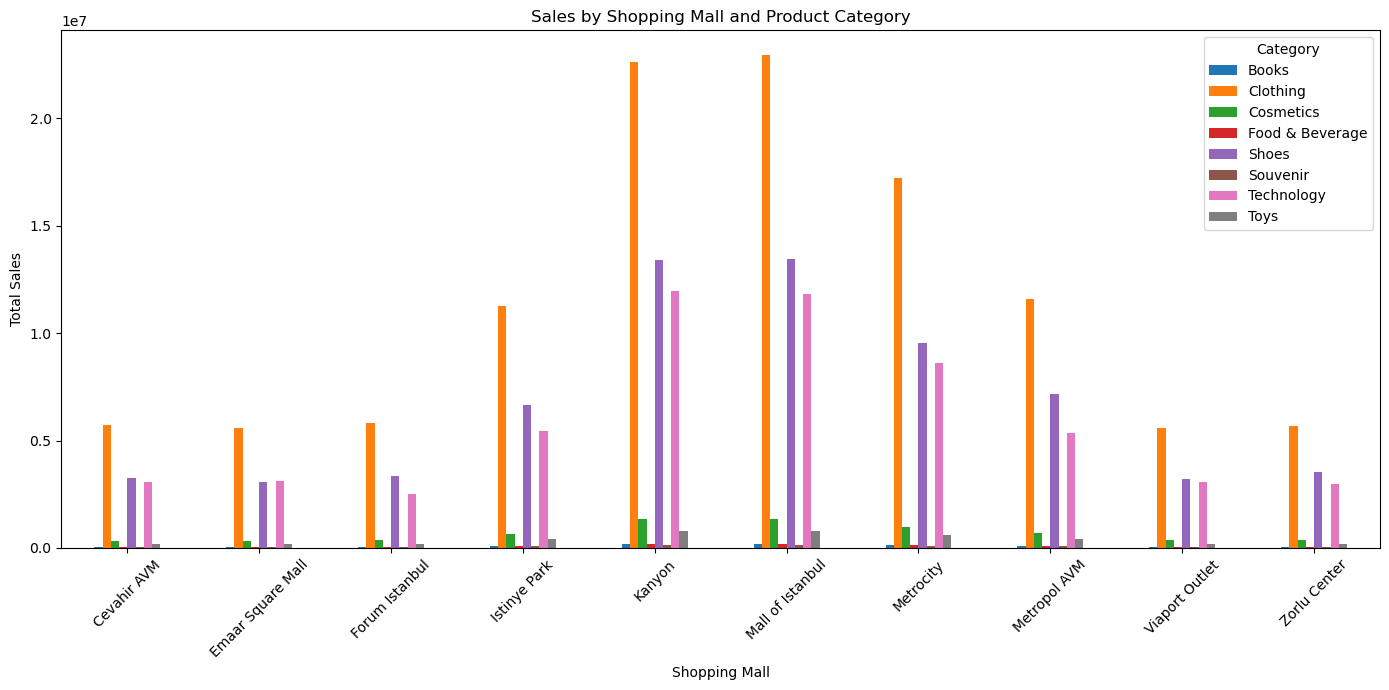

In [9]:
pivot.plot(kind="bar", figsize=(14, 7))

plt.title("Sales by Shopping Mall and Product Category")
plt.xlabel("Shopping Mall")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.legend(title="Category")

plt.tight_layout()
plt.show()

In [10]:
# Total sales by shopping mall
mall_sales = df.groupby("shopping_mall")["sales_amount"].sum()

# Sort for easy comparison
mall_comparison = mall_sales.sort_values(ascending=False)

print("Sales Comparison by Shopping Mall:")
display(mall_comparison)

Sales Comparison by Shopping Mall:


shopping_mall
Mall of Istanbul     50872481.68
Kanyon               50554231.10
Metrocity            37302787.33
Metropol AVM         25379913.19
Istinye Park         24618827.68
Zorlu Center         12901053.82
Cevahir AVM          12645138.20
Viaport Outlet       12521339.72
Emaar Square Mall    12406100.29
Forum Istanbul       12303921.24
Name: sales_amount, dtype: float64

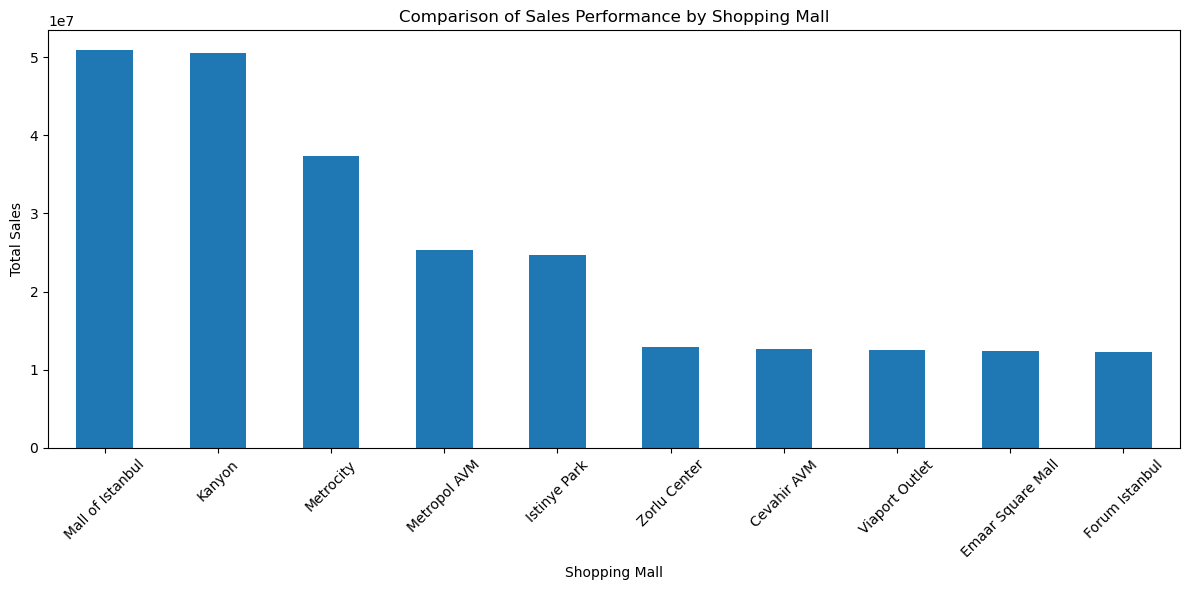

In [11]:
plt.figure(figsize=(12, 6))

mall_comparison.plot(kind="bar")

plt.title("Comparison of Sales Performance by Shopping Mall")
plt.xlabel("Shopping Mall")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
category_comparison = (
    df.groupby("category")["sales_amount"]
    .sum()
    .sort_values(ascending=False)
)

print("Sales Comparison by Product Category:")
display(category_comparison)

Sales Comparison by Product Category:


category
Clothing           1.139968e+08
Shoes              6.655345e+07
Technology         5.786235e+07
Cosmetics          6.792863e+06
Toys               3.980426e+06
Food & Beverage    8.495351e+05
Books              8.345529e+05
Souvenir           6.358247e+05
Name: sales_amount, dtype: float64

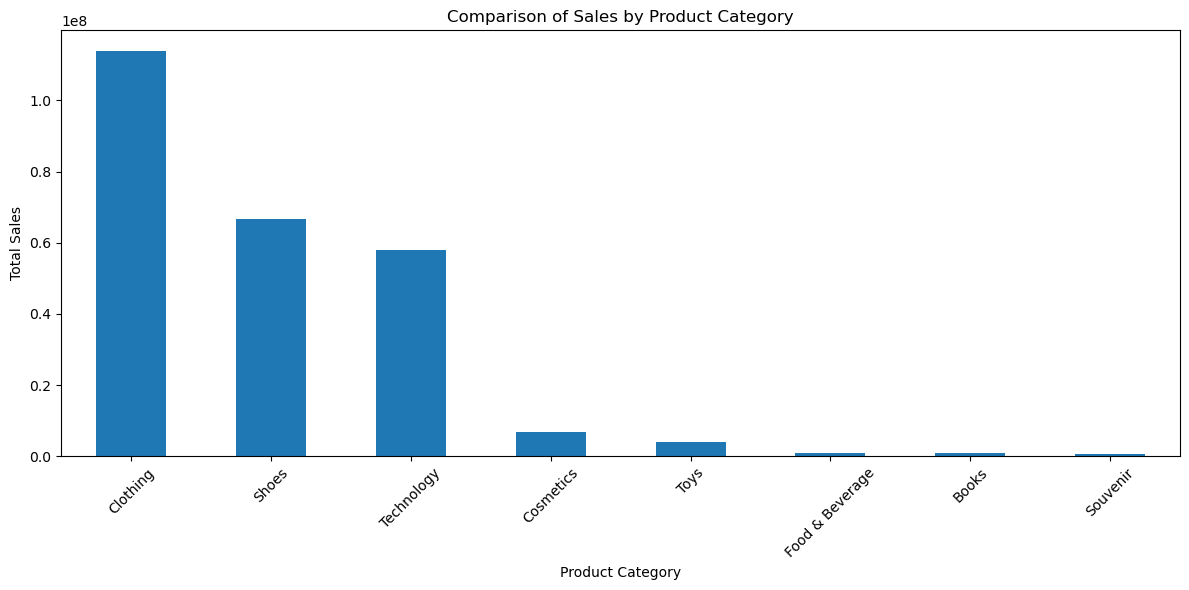

In [13]:
plt.figure(figsize=(12, 6))

category_comparison.plot(kind="bar")

plt.title("Comparison of Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [14]:
avg_sales = (
    df.groupby("shopping_mall")["sales_amount"]
    .mean()
    .sort_values(ascending=False)
)

display(avg_sales)

shopping_mall
Emaar Square Mall    2578.694718
Mall of Istanbul     2550.894132
Kanyon               2550.281547
Viaport Outlet       2548.095181
Zorlu Center         2542.079570
Cevahir AVM          2533.588099
Istinye Park         2517.005181
Metropol AVM         2497.777108
Forum Istanbul       2487.148017
Metrocity            2485.030133
Name: sales_amount, dtype: float64

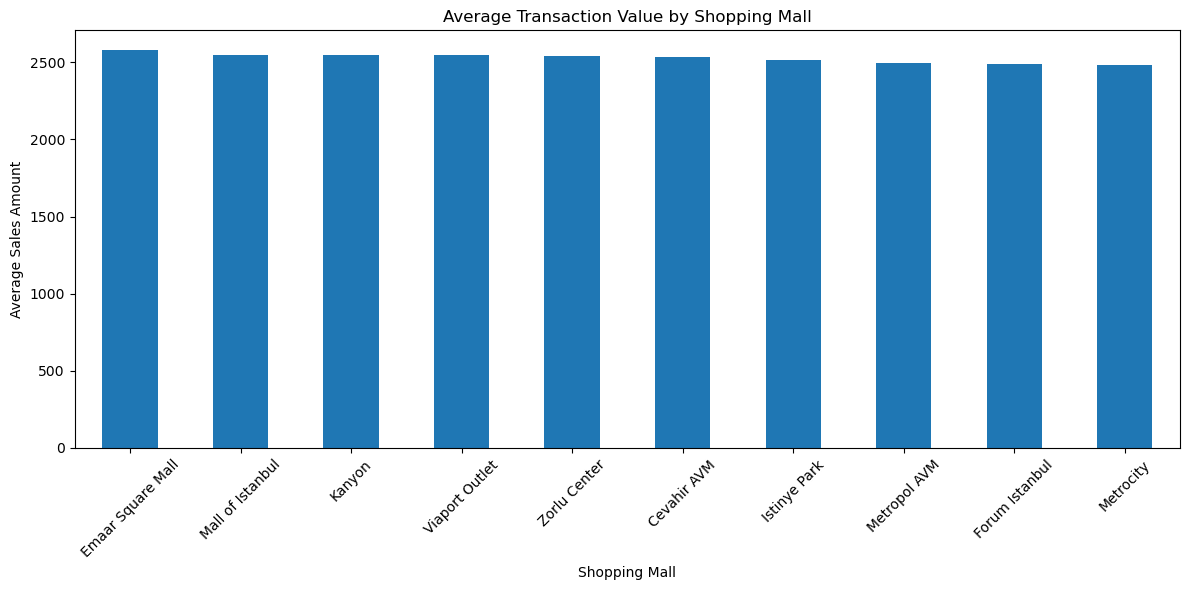

In [15]:
plt.figure(figsize=(12, 6))

avg_sales.plot(kind="bar")

plt.title("Average Transaction Value by Shopping Mall")
plt.xlabel("Shopping Mall")
plt.ylabel("Average Sales Amount")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()